# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [44]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

In [45]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [46]:
display(plans.head())

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [47]:
display(users.head())

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [48]:
display(usage.head())

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [49]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [50]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [51]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [52]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [53]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [54]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

1. Dataset users
city (11.73% de nulos):

Diagnóstico: Un porcentaje moderado de registros carecen de ciudad.

Acción recomendada: Imputar rellenando los valores faltantes con una categoría por defecto como "Desconocida" para evitar descartar a los usuarios.

churn_date (88.35% de nulos):

Diagnóstico: Mayoría aplastante de valores nulos.

Acción recomendada: Mantener los nulos sin modificar. Justificación: Lógicamente, representa a los usuarios que siguen activos y no se han dado de baja del servicio.

2. Dataset usage
date (0.13% de nulos):

Diagnóstico: Una proporción extremadamente baja de fechas faltantes.

Acción recomendada: Eliminar las filas afectadas. Justificación: Al ser menos del 1%, removerlos no afectará significativamente el tamaño del dataset.

duration (55.19% de nulos) y length (44.74% de nulos):

Diagnóstico: Porcentajes elevados de valores ausentes.

Acción recomendada: Investigar segmentando por la columna type. Justificación: Dependiendo del tipo de consumo (por ejemplo, llamadas frente a mensajes de texto o uso de datos), es normal que ciertas métricas no apliquen y queden vacías de forma estructural.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [55]:
print(users['user_id'].describe())
print(users['age'].describe())

count     4000.000000
mean     11999.500000
std       1154.844867
min      10000.000000
25%      10999.750000
50%      11999.500000
75%      12999.250000
max      13999.000000
Name: user_id, dtype: float64
count    4000.000000
mean       33.739750
std       123.232257
min      -999.000000
25%        32.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64


- La columna `user_id` tiene como indicadores rangos normales por lo que no hay nada raro.
- La columna `age` indica en el valor minimo un valor -999 lo que los convierte en un valor atipico y por lo cual deberiamos de hacer una limpieza.

In [56]:
print(usage['id'].describe())
print(usage['user_id'].describe())
print(usage['duration'].describe())
print(usage['length'].describe())

count    40000.00000
mean     20000.50000
std      11547.14972
min          1.00000
25%      10000.75000
50%      20000.50000
75%      30000.25000
max      40000.00000
Name: id, dtype: float64
count    40000.000000
mean     12002.405975
std       1157.279564
min      10000.000000
25%      10996.000000
50%      12013.000000
75%      13005.000000
max      13999.000000
Name: user_id, dtype: float64
count    17924.000000
mean         5.202237
std          6.842701
min          0.000000
25%          1.437500
50%          3.500000
75%          6.990000
max        120.000000
Name: duration, dtype: float64
count    22104.000000
mean        52.127398
std         56.611183
min          0.000000
25%         37.000000
50%         50.000000
75%         64.000000
max       1490.000000
Name: length, dtype: float64



- Las columnas `id` y `user_id`muestran valores de comportamiento razonable ya que el minimo y maximo poseen valores manejables
- La columna 'duration' tiene un valor minimo de '0' que se podria tomar como razonable por diferentes cuasas pero el valor maximo de '120' si se deberia revisar ya que varia demasiado con el valor del 75%.
- La columna 'length'tiene como valor maximo '1490' por lo que al igual que duration dista bastante del 75% y esto podria generar un posible sentinel.


In [57]:

columnas_user = ['city', 'plan']
for col in columnas_user:
    print(users[col].unique())



['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
['Basico' 'Premium']


- La columna `city` nos arroja 2 valores que llaman la atencion el caracter'?' el cual parece ser un sentinel ya que puede ser un valor desconocido, un error o faltante; y 'nan' que se lo poderia tomar como un valor nulo.
- La columna `plan` los valores que nos indica son razonables.

In [58]:
print(usage['type'].unique()) 

['call' 'text']


- La columna `type` refleja dos valores completamente normales.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?
  
Diagnóstico de Valores Inválidos y Sentinels

Columna age (en users):

Hallazgo: Se detectó un valor mínimo de -999, lo cual representa un sentinel evidente o un error de codificación para datos faltantes o inválidos, ya que la edad no puede ser negativa.

Acción recomendada: Filtrar o reemplazar estos valores negativos convirtiéndolos en nulos (NaN) para luego poder imputarlos (por ejemplo, con la mediana o la media de la edad) o eliminarlos según convenga.

Columna city (en users):

Hallazgo: Se encontró el carácter ? junto con valores nulos (nan), los cuales actúan como valores inválidos o sentinels que ocultan información de la ciudad real.

Acción recomendada: Reemplazar el signo ? por valores nulos (NaN) para unificarlos con los registros faltantes y posteriormente tratarlos de manera conjunta (por ejemplo, rellenando con una categoría genérica como "Desconocida").

Columnas duration y length (en usage):

Hallazgo: Aunque sus valores mínimos (0) son posibles, sus valores máximos (120 y 1490 respectivamente) se alejan drásticamente del percentil 75, lo que sugiere la presencia de valores atípicos (outliers) extremos o posibles anomalías en el registro.

Acción recomendada: Analizar la distribución mediante gráficos de caja (boxplot) o segmentar por el tipo de uso (type) para determinar si son casos legítimos de alto consumo o si corresponden a errores de medición que deban ser acotados o tratados.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [59]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     4000 non-null   int64         
 1   first_name  4000 non-null   object        
 2   last_name   4000 non-null   object        
 3   age         4000 non-null   int64         
 4   city        3531 non-null   object        
 5   reg_date    4000 non-null   datetime64[ns]
 6   plan        4000 non-null   object        
 7   churn_date  466 non-null    object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 250.1+ KB


In [60]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   id        40000 non-null  int64         
 1   user_id   40000 non-null  int64         
 2   type      40000 non-null  object        
 3   date      39950 non-null  datetime64[ns]
 4   duration  17924 non-null  float64       
 5   length    22104 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.8+ MB


In [61]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

En `reg_date`, los valores que se presentan son normales.

In [62]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date`, aparace un valor "nan" lo que me indica que algun valor quedo como n  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?
Diagnóstico de Fechas y Años Fuera de Rango
Columna reg_date (en users):

Hallazgo: Al revisar los años únicos, se detecta la presencia del año 2026. Dado que los datos registrados se limitan temporalmente hasta el año 2024, este año representa una anomalía (un año futuro/imposible para la fecha de registro histórica).

Acción recomendada: Filtrar o corregir los registros que contengan fechas posteriores a 2024 (como el año 2026), convirtiéndolas en valores nulos (NaN) o eliminando dichas filas si se trata de errores de captura insalvables.

Columna date (en usage):

Hallazgo: Los años detectados se concentran correctamente en 2024, acompañados de valores nan (nulos). Estos valores nulos corresponden a los registros que ya se habían identificado previamente al convertir la columna (debido a filas donde faltaba el dato de la fecha).

Acción recomendada: Mantener la conversión a tipo fecha de manera robusta (usando errors='coerce' para evitar fallos si hay textos mal formados) y gestionar los valores nulos resultantes según el porcentaje menor al 1% detectado en el paso anterior.
  

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [63]:

age_mediana = users.loc[users['age']!= -999,'age'].median()
users.loc[users['age']== -999,'age']= age_mediana
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [64]:

users.loc[users['city'] == '?','city']=pd.NA
users['city'].describe()


count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [65]:

users.loc[(users['reg_date'].dt.year < 2022) | (users['reg_date'].dt.year > 2024),'reg_date'] = pd.NaT
users['reg_date'].dt.year.unique()

array([2022.,   nan, 2023., 2024.])

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [66]:

usage[usage['duration'].isna()]['type'].value_counts()

text    22076
Name: type, dtype: int64

In [67]:

usage[usage['length'].isna()]['type'].value_counts()

call    17896
Name: type, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Diagnóstico para duration:

Los valores nulos en la columna duration se concentran de forma exclusiva cuando type == 'text' (22,076 registros). Esto confirma que la ausencia de datos depende de la variable type, cumpliendo con el criterio MAR (Missing At Random) —o de carácter estructural—.

Decisión: Se decide dejarlos como nulos (NaN). Los mensajes de texto no poseen una duración temporal como las llamadas, por lo que imputar un valor (como ceros o la media) distorsionaría el análisis estadístico del tiempo de duración.

Diagnóstico para length:

Los valores nulos en la columna length ocurren únicamente cuando type == 'call' (17,896 registros). Al igual que el caso anterior, el patrón de nulos depende directamente de la columna type, confirmando también un comportamiento MAR.

Decisión: Se decide dejarlos como nulos (NaN). Las llamadas telefónicas no manejan el concepto de longitud de la misma manera que los mensajes de texto, por lo que mantenerlos como nulos preserva la integridad de los datos sin sesgar las métricas.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [68]:

usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


usage_agg = usage.groupby('user_id').agg({'is_text':'sum','is_call':'sum','duration':'sum'}).reset_index()


usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [69]:

usage_agg = usage_agg.rename(columns={'is_text':'cant_mensajes','is_call':'cant_llamadas','duration':'cant_minutos_llamada'})

usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [70]:

user_profile = users.merge(usage_agg,on = 'user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [71]:
# Resumen estadístico de las columnas numéricas
user_profile[['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


In [72]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

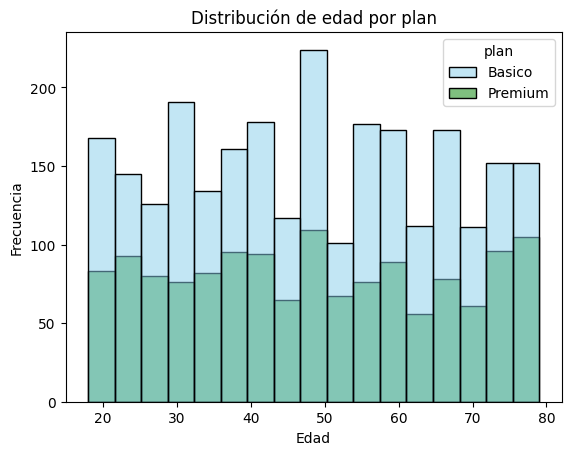

In [73]:
# Histograma para visualizar la edad (age)

sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de edad por plan')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()


💡Insights: 
- Distribución, se puede observar una forma simetrica, la concentracion de edades estan entre los 45 y 50 años, los rangos entre ambos planes es similar.

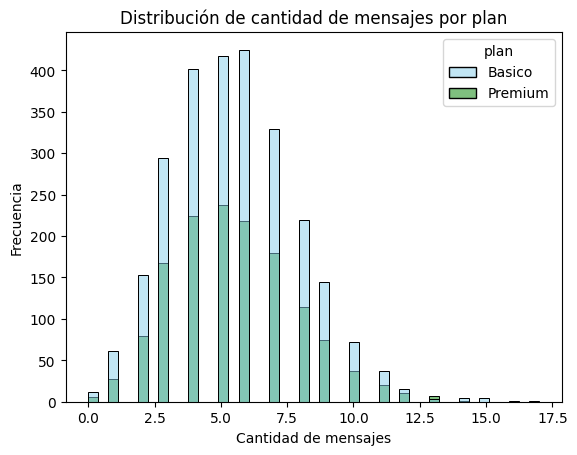

In [74]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de cantidad de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- La distribucion se puede observar que tiene un sesgo hacia la derecha donde se ubican los valores mas bajos, la cantidad de mensajes se concentra entre 6 y 7 con mayor frecuencia al plan basico. 

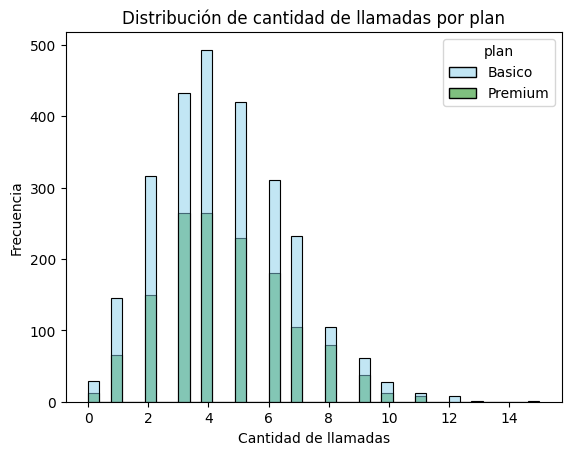

In [75]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de cantidad de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución sesgada hacia la derecha, la mayor cantidad de llamadas se concentran en un valor de 3 a 5 llamadas donde el plan basico tiene mayor frecuencia. 

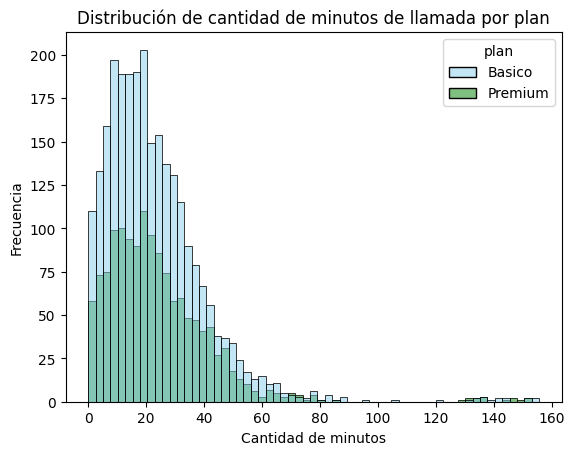

In [76]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue','green'])
plt.title('Distribución de cantidad de minutos de llamada por plan')
plt.xlabel('Cantidad de minutos')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- La distribucion para la cantidad de minutos por llamada tambien tiene un claro sesgo hacia la derecha donde estan los valores bajos, por lo que entre 10 y 25 minutos es la cantidad de duracion de las llamadas con mayor porcentaje y con un claro referente hacia el plan basico. 

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

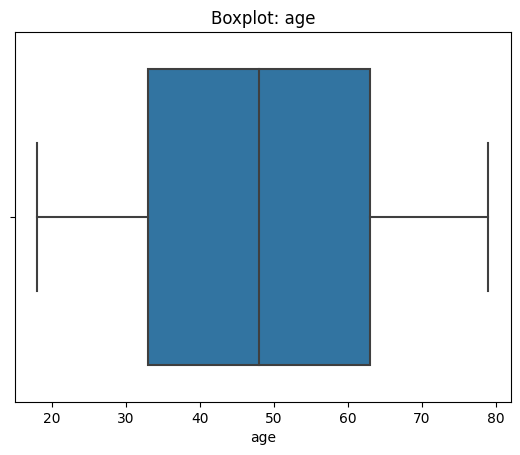

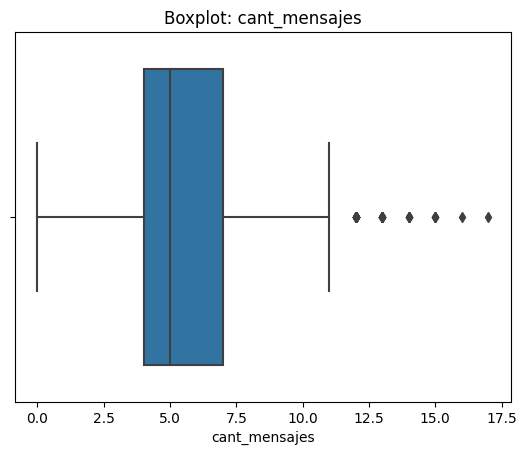

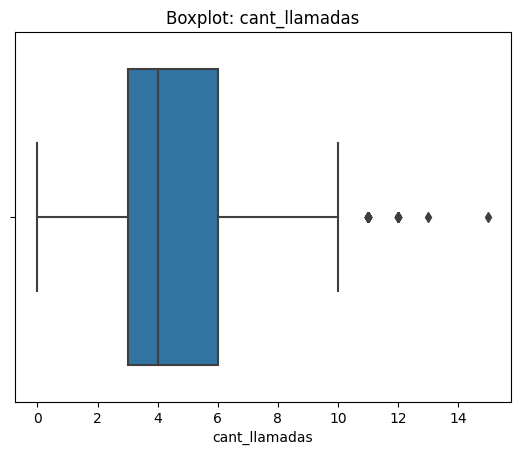

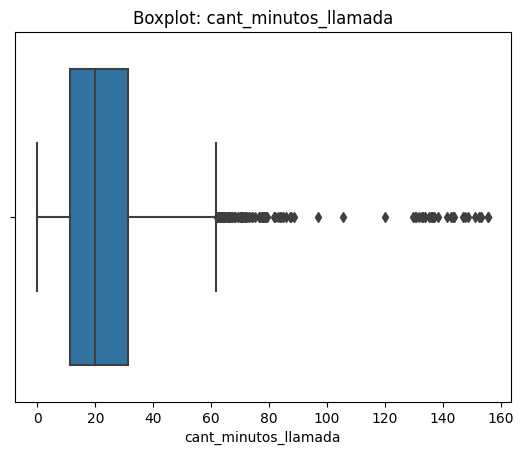

In [77]:
# Visualizando usando BoxPlot 

columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()


💡Insights: 
- Age: No presenta outliers por lo que hay una distribucion equitativa en las edades
- cant_mensajes: Si presenta outliers que se distribuyen a valores altos lo cual significa que hay una tendencia a uso de mensajes mas frecuentes.
- cant_llamadas: De igual manera presenta outliers con distribucion a valores altos por lo que indica que existe un grupo de usuarios que realiza una cantidad de llamadas mucho mayor que el  resto
- cant_minutos_llamada: La tendencia se mantiene hacia los valores mas altos por lo que el tiempo de duracion de las llamadas fue mayor para un grupo de usuarios

In [78]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes','cant_llamadas','cant_minutos_llamada']
for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    IQR = q3 - q1
    limite_superior = q3 + 1.5 * IQR
    print(col, limite_superior)


cant_mensajes 11.5
cant_llamadas 10.5
cant_minutos_llamada 61.8575


In [79]:
print((user_profile['cant_mensajes'] > 11.5).sum())
print((user_profile['cant_llamadas'] > 10.5).sum())
print((user_profile['cant_minutos_llamada'] > 61.8575).sum())
len(user_profile)

46
30
109


4000

In [80]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
limite_superior = q3 + 1.5 * IQR
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000



💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
  El porcerntaje de outliers es 1.15% lo que representa un valor bajo por lo que SE lo puedes mantener para un futuro analisis
- cant_llamadas: mantener o no outliers, porqué?
  De igual manera en esta columna hay un porcentaje bajo de outliers con un 0.75% lo cual seria manejable para el analisis
- cant_minutos_llamada: mantener o no outliers, porqué?
  En este caso si deberiamos de enfocar otras estrategias ya que los outliers tienen un pocertanje alto 2.725%, y esto podria afectarnos en el analisis por cierto grupo de clientes que realizan llamadas de mayor duracion 


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [81]:
# Crear columna grupo_uso
def grupo_uso(row):
    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

In [82]:
user_profile['grupo_uso'] = user_profile.apply(grupo_uso, axis=1)

In [83]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [84]:
# Crear columna grupo_edad
def grupo_edad(row):
    if row['age'] < 30:
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

In [85]:
user_profile['grupo_edad'] = user_profile.apply(grupo_edad, axis=1)

In [86]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

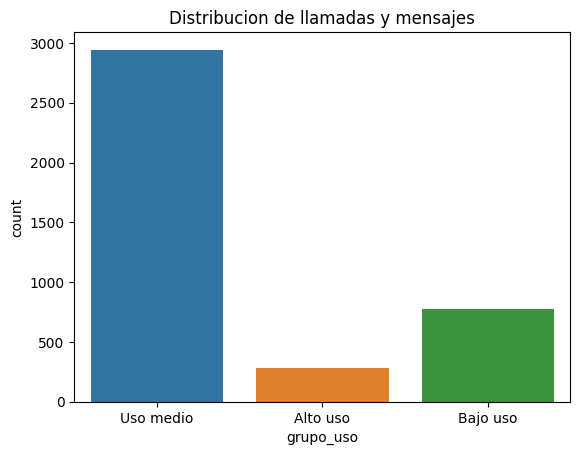

In [94]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.title('Distribucion de llamadas y mensajes')
plt.show()

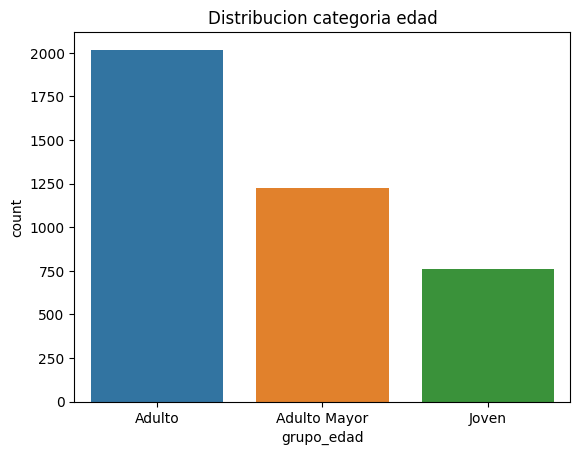

In [96]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.title('Distribucion categoria edad')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
  
  Dataset users:
  Columna city: Presentaba valores nulos y el carácter centinela '?'. En total, los registros sin ciudad ascendían a 469, lo que representaba un 11.73% del total de usuarios.
  Columna churn_date: Contenía 3,534 valores nulos, lo que equivalía al 88.35% de los registros. Este valor no era un error, sino un reflejo estructural de los clientes que se mantienen activos en la compañía.
  Columna age: Contenía un valor centinela extremo de -999, representando una edad inválida.
  Columna reg_date: Incluía registros con fechas en el año 2026, lo cual excedía el límite temporal histórico establecido hasta 2024.
  
  Dataset usage:
  Columna date: Contenía 50 valores nulos, representando un porcentaje mínimo del 0.13%.
  Columnas duration y length: Presentaban un alto porcentaje de nulos (55.19% en duration y 44.74% en length). Se comprobó que se trataba de nulos estructurales (MAR / Missing At Random) debidos a la naturaleza de la variable type: las llamadas no registran longitud de texto y los mensajes de texto no registran duración de llamada.   

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?
  
Segmentación por Plan: Los clientes se dividen en dos grandes grupos: el Plan Básico (que abarca al 64.87% de los usuarios) y el Plan Premium (con el 35.12%).
Comportamiento por Edad: La distribución de las edades es simétrica y se concentra mayoritariamente entre los 45 y 50 años, con un comportamiento demográfico muy similar en ambos planes.
Nivel de Uso: Las métricas de consumo (mensajes, llamadas y minutos) muestran distribuciones sesgadas a la derecha, lo que indica que la gran mayoría de los usuarios mantiene un consumo moderado-bajo. Los usuarios del plan Básico concentran las frecuencias más altas en los rangos inferiores de uso. 
  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

  
El segmento Premium destaca como el más valioso en términos de contribución directa a los ingresos, ya que pagan una tarifa mensual superior (25 USD frente a los 12 USD del plan Básico) y consumen mayores volúmenes de servicios incluidos (20 GB, 500 mensajes, 600 minutos).Sin embargo, el segmento Básico (64.87%) representa una base masiva de volumen que sostiene la penetración de mercado de la empresa, siendo ideal para estrategias de upselling hacia el plan superior.   
  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

  
Se detectaron valores máximos extremos en la tabla de uso, tales como duraciones de llamadas de hasta 120 minutos y longitudes de mensajes de hasta 1,490, los cuales se alejan drásticamente del percentil 75.
Implicaciones para el negocio: Estos valores atípicos reflejan la presencia de "power users" o clientes con necesidades de conectividad muy elevadas. Para el negocio, representan una oportunidad directa de monetización por excedentes de tarifas extra (usd_per_gb, usd_per_minute, usd_per_message) o una señal clara de que ciertos clientes necesitan planes con mayores límites.   

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?
  
Diseñar un plan intermedio: La brecha de precio y beneficios entre el plan Básico (12 USD) y el Premium (25 USD) es amplia. Un plan intermedio (por ejemplo, de 17-18 USD) permitiría capturar a aquellos usuarios del plan Básico cuyo consumo está creciendo pero que consideran el plan Premium demasiado costoso.
 Estrategias comerciales orientadas por edad: Dado que el núcleo de los usuarios se concentra en la franja de 45 a 50 años, se recomienda enfocar la comunicación y los beneficios adicionales (como paquetes de datos para mensajería o llamadas internacionales) a los intereses de este segmento demográfico.
Automatización de alertas de consumo: Implementar notificaciones proactivas para los usuarios que se acerquen a los límites de sus planes, ofreciéndoles opciones de mejora de plan (upgrade) antes de que acumulen cargos excesivos por tarifas adicionales.

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Tras una fase de depuración se corrigió anomalías aisladas (edades centinela, fechas fuera de rango y un 11.7% de ciudades faltantes), se validó que los vacíos restantes responden a comportamientos estructurales del negocio, garantizando una base sólida y confiable para la segmentación.


🔍 **Segmentos por Edad**
La distribución etaria es simétrica y se concentra mayoritariamente entre los 45 y 50 años, con un comportamiento demográfico muy homogéneo en ambos planes.


📊 **Segmentos por Nivel de Uso**
El Segmento Premium: Representa el mayor valor en términos de contribución directa a los ingresos gracias a su tarifa mensual superior (25 USD) y su consumo elevado de servicios incluidos.   
El Segmento Básico: Con un 64.87% de adopción, constituye la base masiva de penetración de mercado y el principal embudo para futuras campañas de conversión y upselling.  


💡 **Recomendaciones**
Diseñar un plan intermedio: Reducir la brecha tarifaria y de beneficios entre el Plan Básico (12 USD) y el Plan Premium (25 USD) mediante la creación de una opción intermedia (aprox. 17-18 USD) que capture el crecimiento de consumo de los usuarios básicos.   
Estrategias comerciales centradas en la edad núcleo: Dirigir las campañas de comunicación, fidelización y servicios complementarios al segmento demográfico clave de 45 a 50 años.  
Automatización de alertas de consumo: Implementar notificaciones proactivas para los usuarios que se acerquen a los límites de sus planes, permitiéndoles gestionar su consumo o migrar de plan antes de acumular cargos excesivos por tarifas adicionales. 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

In [ ]:
https://github.com/Andreslcc86/Analisis_de_empresa_de_telecomunicaciones.git